In [3]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append('..')

import json
import numpy as np

import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable

from tqdm import tqdm

mpl.rc('text', usetex=True)
mpl.rcParams['text.latex.preamble'] = r"\usepackage{amsmath} \usepackage{xfrac}"

tex_fonts = {"font.family": "serif",
             "font.size": 11,
             "axes.labelsize": 11,
             "legend.fontsize": 11,
             "xtick.labelsize": 8,
             "ytick.labelsize": 8}

plt.rcParams.update(tex_fonts)

marker_options = {'marker': 'o',
                  'markeredgecolor': 'black',
                  'markeredgewidth': 1.0,
                  'markersize': 5}

cmap = sns.color_palette('deep', as_cmap=True)

def set_size(width="revtex4.2", fraction=1, subplots=(1, 1), golden_ratio = 0.6180339887498949):
    """Set figure dimensions to avoid scaling in LaTeX.

    Parameters
    ----------
    width: float or string
            Document width in points, or string of predined document type
    fraction: float, optional
            Fraction of the width which you wish the figure to occupy
    subplots: array-like, optional
            The number of rows and columns of subplots.
    Returns
    -------
    fig_dim: tuple
            Dimensions of figure in inches
    """
    if width == 'revtex4.2':
        width_pt = 510.0
    else:
        width_pt = width

    # Width of figure (in pts)
    fig_width_pt = width_pt * fraction
    # Convert from pt to inches
    inches_per_pt = 1 / 72.27

    # Figure width in inches
    fig_width_in = fig_width_pt * inches_per_pt
    # Figure height in inches
    fig_height_in = fig_width_in * golden_ratio * (subplots[0] / subplots[1])

    return (fig_width_in, fig_height_in)

def load_training_results(file_name: str, data_folder = "../data/optimisation_data/"):
    """
    Save results of the function 'optimize_tn' in json format. 
    Complex values are transformed into strings for json serialisation.
    """
    with open(data_folder + file_name, 'r') as file:
        res = json.load(file)

        # Params during training
        res['params'] = [{int(k): np.array(v, dtype=complex) for k, v in p.items()} for p in res['params']]

        # Params of the MPOs, self-explanatory
        mpo_params_keys = [] #['params_true_mpo', 'params_inv_opt_mpo', 'params_inv_true_mpo']
        for key in mpo_params_keys:
            res[key] = {int(k): np.real_if_close(np.array(v, dtype=complex)) for k, v in res[key].items()}
        
        ignore_keys = ['probs', 'data_file', 'params', 'noise_type', 'lr', 'params_true_mpo', 'params_inv_opt_mpo', 'params_inv_true_mpo'] + mpo_params_keys
        for k in set(res.keys()).difference(ignore_keys):
            res[k] = np.real_if_close(np.array(res[k], dtype=complex))
        
    return res

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [4]:
coherent_depol = {'1e3': ['cxeven_nq10_coherent1e-3_even_depol1e-3_odd_depol5e-4_ns1000_global_repeated_sic_states_2023-11-22_seed13.json',
                          'cxeven_nq10_coherent1e-3_even_depol1e-3_odd_depol5e-4_ns1000_global_repeated_sic_states_2023-11-22_seed14.json',
                          'cxeven_nq10_coherent1e-3_even_depol1e-3_odd_depol5e-4_ns1000_global_repeated_sic_states_2023-11-22_seed15.json'],
                  '1e4': ['cxeven_nq10_coherent1e-3_even_depol1e-3_odd_depol5e-4_ns10000_global_repeated_sic_states_2023-11-22_seed13.json',
                          'cxeven_nq10_coherent1e-3_even_depol1e-3_odd_depol5e-4_ns10000_global_repeated_sic_states_2023-11-22_seed14.json',
                          'cxeven_nq10_coherent1e-3_even_depol1e-3_odd_depol5e-4_ns10000_global_repeated_sic_states_2023-11-22_seed15.json'],
                  '1e5': ['cxeven_nq10_coherent1e-3_even_depol1e-3_odd_depol5e-4_ns100000_global_repeated_sic_states_2023-11-22_seed13.json',
                          'cxeven_nq10_coherent1e-3_even_depol1e-3_odd_depol5e-4_ns100000_global_repeated_sic_states_2023-11-22_seed14.json',
                          'cxeven_nq10_coherent1e-3_even_depol1e-3_odd_depol5e-4_ns100000_global_repeated_sic_states_2023-11-22_seed15.json'],
                  '1e6': ['cxeven_nq10_coherent1e-3_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-22_seed13.json',
                          'cxeven_nq10_coherent1e-3_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-22_seed14.json',
                          'cxeven_nq10_coherent1e-3_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-22_seed15.json'],
                  '1e7': ['cxeven_nq10_coherent1e-3_even_depol1e-3_odd_depol5e-4_ns10000000_global_repeated_sic_states_2023-11-16_seed13.json',
                          'cxeven_nq10_coherent1e-3_even_depol1e-3_odd_depol5e-4_ns10000000_global_repeated_sic_states_2023-11-16_seed13.json',
                          'cxeven_nq10_coherent1e-3_even_depol1e-3_odd_depol5e-4_ns10000000_global_repeated_sic_states_2023-11-16_seed101.json']}

depol = {'1e3': ['cxeven_nq10_even_depol1e-3_odd_depol5e-4_ns1000_global_repeated_sic_states_2023-11-22_seed13.json',
                 'cxeven_nq10_even_depol1e-3_odd_depol5e-4_ns1000_global_repeated_sic_states_2023-11-22_seed14.json',
                 'cxeven_nq10_even_depol1e-3_odd_depol5e-4_ns1000_global_repeated_sic_states_2023-11-22_seed15.json'],
         '1e4': ['cxeven_nq10_even_depol1e-3_odd_depol5e-4_ns10000_global_repeated_sic_states_2023-11-22_seed13.json',
                 'cxeven_nq10_even_depol1e-3_odd_depol5e-4_ns10000_global_repeated_sic_states_2023-11-22_seed14.json',
                 'cxeven_nq10_even_depol1e-3_odd_depol5e-4_ns10000_global_repeated_sic_states_2023-11-22_seed15.json'],
         '1e5': ['cxeven_nq10_even_depol1e-3_odd_depol5e-4_ns100000_global_repeated_sic_states_2023-11-22_seed13.json',
                 'cxeven_nq10_even_depol1e-3_odd_depol5e-4_ns100000_global_repeated_sic_states_2023-11-22_seed14.json',
                 'cxeven_nq10_even_depol1e-3_odd_depol5e-4_ns100000_global_repeated_sic_states_2023-11-22_seed15.json'],
         '1e6': ['cxeven_nq10_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-09_seed13.json',
                 'cxeven_nq10_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-09_seed14.json',
                 'cxeven_nq10_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-09_seed15.json'],
         '1e7': ['cxeven_nq10_even_depol1e-3_odd_depol5e-4_ns10000000_global_repeated_sic_states_2023-11-13_seed99.json',
                 'cxeven_nq10_even_depol1e-3_odd_depol5e-4_ns10000000_global_repeated_sic_states_2023-11-13_seed718.json',
                 'cxeven_nq10_even_depol1e-3_odd_depol5e-4_ns10000000_global_repeated_sic_states_2023-11-13_seed999.json']}


spl_hanoi = {'1e3': ['cxeven_nq10_noise_model_coef_ibm_hanoi_10qchain25_dd_inst1_layer0_unit_100_100s_ns1000_global_repeated_sic_states_2023-11-22_seed13.json',
                     'cxeven_nq10_noise_model_coef_ibm_hanoi_10qchain25_dd_inst1_layer0_unit_100_100s_ns1000_global_repeated_sic_states_2023-11-22_seed14.json',
                     'cxeven_nq10_noise_model_coef_ibm_hanoi_10qchain25_dd_inst1_layer0_unit_100_100s_ns1000_global_repeated_sic_states_2023-11-22_seed13.json'],
             '1e4': ['cxeven_nq10_noise_model_coef_ibm_hanoi_10qchain25_dd_inst1_layer0_unit_100_100s_ns10000_global_repeated_sic_states_2023-11-22_seed13.json',
                     'cxeven_nq10_noise_model_coef_ibm_hanoi_10qchain25_dd_inst1_layer0_unit_100_100s_ns10000_global_repeated_sic_states_2023-11-22_seed14.json',
                     'cxeven_nq10_noise_model_coef_ibm_hanoi_10qchain25_dd_inst1_layer0_unit_100_100s_ns10000_global_repeated_sic_states_2023-11-22_seed15.json'],
             '1e5': ['cxeven_nq10_noise_model_coef_ibm_hanoi_10qchain25_dd_inst1_layer0_unit_100_100s_ns100000_global_repeated_sic_states_2023-11-22_seed13.json',
                     'cxeven_nq10_noise_model_coef_ibm_hanoi_10qchain25_dd_inst1_layer0_unit_100_100s_ns100000_global_repeated_sic_states_2023-11-22_seed14.json',
                     'cxeven_nq10_noise_model_coef_ibm_hanoi_10qchain25_dd_inst1_layer0_unit_100_100s_ns100000_global_repeated_sic_states_2023-11-22_seed15.json'],
             '1e6': ['cxeven_nq10_noise_model_coef_ibm_hanoi_10qchain25_dd_inst1_layer0_unit_100_100s_ns1000000_global_repeated_sic_states_2023-11-22_seed13.json',
                     'cxeven_nq10_noise_model_coef_ibm_hanoi_10qchain25_dd_inst1_layer0_unit_100_100s_ns1000000_global_repeated_sic_states_2023-11-22_seed14.json',
                     'cxeven_nq10_noise_model_coef_ibm_hanoi_10qchain25_dd_inst1_layer0_unit_100_100s_ns1000000_global_repeated_sic_states_2023-11-22_seed15.json'],
             '1e7': ['cxeven_nq10_noise_model_coef_ibm_hanoi_10qchain25_dd_inst1_layer0_unit_100_100s_ns10000000_global_repeated_sic_states_2023-11-08_seed10.json',
                     'cxeven_nq10_noise_model_coef_ibm_hanoi_10qchain25_dd_inst1_layer0_unit_100_100s_ns10000000_global_repeated_sic_states_2023-11-08_seed13.json',
                     'cxeven_nq10_noise_model_coef_ibm_hanoi_10qchain25_dd_inst1_layer0_unit_100_100s_ns10000000_global_repeated_sic_states_2023-11-08_seed99.json']                                                         
             }


spl_kyiv = {'1e3': ['cxeven_nq10_gen_dict_bigger_231127_kyiv_50q_ns1000_global_repeated_sic_states_2023-11-29_seed13.json',
                    'cxeven_nq10_gen_dict_bigger_231127_kyiv_50q_ns1000_global_repeated_sic_states_2023-11-29_seed14.json',
                    'cxeven_nq10_gen_dict_bigger_231127_kyiv_50q_ns1000_global_repeated_sic_states_2023-11-29_seed15.json'],
            '1e4': ['cxeven_nq10_gen_dict_bigger_231127_kyiv_50q_ns10000_global_repeated_sic_states_2023-11-29_seed26.json',
                    'cxeven_nq10_gen_dict_bigger_231127_kyiv_50q_ns10000_global_repeated_sic_states_2023-11-29_seed27.json',
                    'cxeven_nq10_gen_dict_bigger_231127_kyiv_50q_ns10000_global_repeated_sic_states_2023-11-29_seed28.json'],
            '1e5': ['cxeven_nq10_gen_dict_bigger_231127_kyiv_50q_ns100000_global_repeated_sic_states_2023-11-29_seed30.json',
                    'cxeven_nq10_gen_dict_bigger_231127_kyiv_50q_ns100000_global_repeated_sic_states_2023-11-29_seed31.json',
                    'cxeven_nq10_gen_dict_bigger_231127_kyiv_50q_ns100000_global_repeated_sic_states_2023-11-29_seed32.json'],    
            '1e6': ['cxeven_nq10_gen_dict_bigger_231127_kyiv_50q_ns1000000_global_repeated_sic_states_2023-11-29_seed46.json',
                    'cxeven_nq10_gen_dict_bigger_231127_kyiv_50q_ns1000000_global_repeated_sic_states_2023-11-29_seed47.json',
                    'cxeven_nq10_gen_dict_bigger_231127_kyiv_50q_ns1000000_global_repeated_sic_states_2023-11-29_seed48.json'],
            '1e7': ['cxeven_nq10_gen_dict_bigger_231127_kyiv_50q_ns10000000_global_repeated_sic_states_2023-11-30_seed100.json',
                    'cxeven_nq10_gen_dict_bigger_231127_kyiv_50q_ns10000000_global_repeated_sic_states_2023-11-30_seed103.json',
                    'cxeven_nq10_gen_dict_bigger_231127_kyiv_50q_ns10000000_global_repeated_sic_states_2023-11-30_seed108.json'],
       }

In [5]:
shots_keys = ['1e3', '1e4', '1e5', '1e6', '1e7']
metrics_keys = ['frob_distance', 'test_loss', 'lpdo_trace']

noise_models = {'depol': depol, 'coherent_depol': coherent_depol, 'spl_kyiv': spl_kyiv, 'spl_hanoi': spl_hanoi}

processed_data = {}
for noise_type, noise_data in noise_models.items():  
    print(f"\nProcessing {noise_type}:")         
    
    best_frob_dists = {k: [] for k in noise_data.keys()}
    for shots, files in noise_data.items():
        
        tmp_dict = {k: [] for k in metrics_keys}
        for f in files:
            print(f" > Loading and processing file: {f}")
            data = load_training_results(f)
            [tmp_dict[k].append(data[k]) for k in tmp_dict.keys()]

        idx_min_loss = [np.argmin(yy) for yy in tmp_dict['test_loss']]
        best_vals = np.array([dist[idx] for dist, idx in zip(tmp_dict['frob_distance'], idx_min_loss)])
        print(best_vals)
        best_vals = np.sort(best_vals)[:3] # pick only the best three values
        best_frob_dists[shots] = np.mean(best_vals), np.std(best_vals)
        print(best_vals)

    processed_data[noise_type] = best_frob_dists

processed_data


Processing depol:
 > Loading and processing file: cxeven_nq10_even_depol1e-3_odd_depol5e-4_ns1000_global_repeated_sic_states_2023-11-22_seed13.json
 > Loading and processing file: cxeven_nq10_even_depol1e-3_odd_depol5e-4_ns1000_global_repeated_sic_states_2023-11-22_seed14.json
 > Loading and processing file: cxeven_nq10_even_depol1e-3_odd_depol5e-4_ns1000_global_repeated_sic_states_2023-11-22_seed15.json
[0.06623066 0.07175746 0.06839914]
[0.06623066 0.06839914 0.07175746]
 > Loading and processing file: cxeven_nq10_even_depol1e-3_odd_depol5e-4_ns10000_global_repeated_sic_states_2023-11-22_seed13.json
 > Loading and processing file: cxeven_nq10_even_depol1e-3_odd_depol5e-4_ns10000_global_repeated_sic_states_2023-11-22_seed14.json
 > Loading and processing file: cxeven_nq10_even_depol1e-3_odd_depol5e-4_ns10000_global_repeated_sic_states_2023-11-22_seed15.json
[0.00901762 0.00669455 0.01105612]
[0.00669455 0.00901762 0.01105612]
 > Loading and processing file: cxeven_nq10_even_depol1e-3

{'depol': {'1e3': (0.06879575281134813, 0.002273667292667692),
  '1e4': (0.008922764752973118, 0.0017818652026902369),
  '1e5': (0.0006975874396831783, 0.000122148792718852),
  '1e6': (4.9291838731998126e-05, 2.8806340542332763e-06),
  '1e7': (1.223343298017987e-05, 1.2504063268652475e-06)},
 'coherent_depol': {'1e3': (0.06795163317910032, 0.004082811912247182),
  '1e4': (0.006839624238314819, 0.0005319774494739381),
  '1e5': (0.000525337237070859, 7.651027124927127e-05),
  '1e6': (6.721373046980617e-05, 8.664027846253835e-07),
  '1e7': (1.490179508067957e-05, 3.640009719187309e-07)},
 'spl_kyiv': {'1e3': (0.12200334810470408, 0.010599172913403261),
  '1e4': (0.007029797845927129, 0.00026125577258570017),
  '1e5': (0.0015149264973592924, 2.424834829933724e-05),
  '1e6': (0.00016145432469893972, 6.910524985451699e-06),
  '1e7': (0.00010207783344551302, 1.0467653064450675e-05)},
 'spl_hanoi': {'1e3': (0.0713848526969753, 0.0004307822078191065),
  '1e4': (0.0069924843091980415, 0.00038882

# Plot with error bars

In [15]:
processed_data

{'depol': {'1e3': (0.06879575281134813, 0.002273667292667692),
  '1e4': (0.008922764752973118, 0.0017818652026902369),
  '1e5': (0.0006975874396831783, 0.000122148792718852),
  '1e6': (4.9291838731998126e-05, 2.8806340542332763e-06),
  '1e7': (1.223343298017987e-05, 1.2504063268652475e-06)},
 'coherent_depol': {'1e3': (0.06795163317910032, 0.004082811912247182),
  '1e4': (0.006839624238314819, 0.0005319774494739381),
  '1e5': (0.000525337237070859, 7.651027124927127e-05),
  '1e6': (6.721373046980617e-05, 8.664027846253835e-07),
  '1e7': (1.490179508067957e-05, 3.640009719187309e-07)},
 'spl_kyiv': {'1e3': (0.12200334810470408, 0.010599172913403261),
  '1e4': (0.007029797845927129, 0.00026125577258570017),
  '1e5': (0.0015149264973592924, 2.424834829933724e-05),
  '1e6': (0.00016145432469893972, 6.910524985451699e-06),
  '1e7': (0.00010207783344551302, 1.0467653064450675e-05)},
 'spl_hanoi': {'1e3': (0.0713848526969753, 0.0004307822078191065),
  '1e4': (0.0069924843091980415, 0.00038882

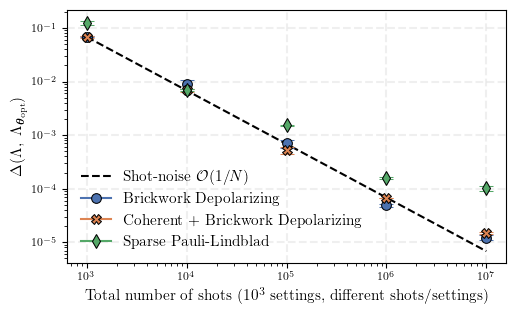

In [6]:
markersize = 7
capsize = 5

markers = ['o', 'X', 'd']
labels = ["Brickwork Depolarizing", "Coherent + Brickwork Depolarizing", "Sparse Pauli-Lindblad", "Sparse Pauli-Lindblad Hanoi"]

shots = np.array([10 ** int(k[2:]) for k in shots_keys])

fig = plt.figure(figsize=set_size(fraction=0.75))

# Shot-noise scaling
plt.plot(shots, 68 * shots**(-1.), color = "k", ls = "--", label = r"Shot-noise $\mathcal{O}(1/N)$")

# Noise with error-bars
for (k, vals_dicts), color, marker, label in zip(processed_data.items(), cmap, markers, labels):

    for s, v in zip(shots, vals_dicts.values()):
        plt.errorbar(s, v[0], yerr = v[1], color = color, marker = marker,  markersize = markersize, capsize = capsize, markeredgecolor='black', capthick=1, mew=0.75)
    plt.errorbar([], [], color = color, marker = marker, markersize = markersize, capsize = capsize, markeredgecolor='black', label=label, mew=0.75)

plt.yscale('log')
plt.xscale('log')
plt.xlabel(r"Total number of shots ($10^3$ settings, different shots/settings)")
plt.ylabel(r"$\Delta(\Lambda,~\Lambda_{\boldsymbol{\theta_\textrm{opt}}})$")

plt.legend(loc=3, frameon=False)

plt.grid(ls = "--", lw = 1.5, alpha = 0.2)

plt.tight_layout()
#plt.savefig('delta_accuracy_vs_shots.pdf', format="pdf")

# Plot without errorbars

In [26]:
shots_keys = ['1e3', '1e4', '1e5', '1e6', '1e7']
metrics_keys = ['frob_distance', 'test_loss', 'lpdo_trace']

noise_models = {'depol': depol, 'coherent_depol': coherent_depol, 'spl_kyiv': spl_kyiv, 'spl_hanoi': spl_hanoi}

processed_data = {}
for noise_type, noise_data in noise_models.items():  
    print(f"\nProcessing {noise_type}:")         
    
    best_frob_dists = {k: [] for k in noise_data.keys()}
    for shots, files in noise_data.items():
        
        tmp_dict = {k: [] for k in metrics_keys}
        for f in files:
            print(f" > Loading and processing file: {f}")
            data = load_training_results(f)
            [tmp_dict[k].append(data[k]) for k in tmp_dict.keys()]

        idx_min_loss = [np.argmin(yy) for yy in tmp_dict['test_loss']]
        best_vals = np.array([dist[idx] for dist, idx in zip(tmp_dict['frob_distance'], idx_min_loss)])
        print(best_vals)
        best_vals = np.sort(best_vals)[:3] # pick only the best three values
        best_frob_dists[shots] = np.min(best_vals), 0 * np.std(best_vals)
        print(best_vals)

    processed_data[noise_type] = best_frob_dists

processed_data


Processing depol:
 > Loading and processing file: cxeven_nq10_even_depol1e-3_odd_depol5e-4_ns1000_global_repeated_sic_states_2023-11-22_seed13.json
 > Loading and processing file: cxeven_nq10_even_depol1e-3_odd_depol5e-4_ns1000_global_repeated_sic_states_2023-11-22_seed14.json
 > Loading and processing file: cxeven_nq10_even_depol1e-3_odd_depol5e-4_ns1000_global_repeated_sic_states_2023-11-22_seed15.json
[0.06623066 0.07175746 0.06839914]
[0.06623066 0.06839914 0.07175746]
 > Loading and processing file: cxeven_nq10_even_depol1e-3_odd_depol5e-4_ns10000_global_repeated_sic_states_2023-11-22_seed13.json
 > Loading and processing file: cxeven_nq10_even_depol1e-3_odd_depol5e-4_ns10000_global_repeated_sic_states_2023-11-22_seed14.json
 > Loading and processing file: cxeven_nq10_even_depol1e-3_odd_depol5e-4_ns10000_global_repeated_sic_states_2023-11-22_seed15.json
[0.00901762 0.00669455 0.01105612]
[0.00669455 0.00901762 0.01105612]
 > Loading and processing file: cxeven_nq10_even_depol1e-3

{'depol': {'1e3': (0.06623066104824103, 0.0),
  '1e4': (0.00669455269643937, 0.0),
  '1e5': (0.0005587770764844402, 0.0),
  '1e6': (4.526245243197114e-05, 0.0),
  '1e7': (1.0505945556738006e-05, 0.0)},
 'coherent_depol': {'1e3': (0.06369893835592533, 0.0),
  '1e4': (0.006251921464741849, 0.0),
  '1e5': (0.00042107298234472795, 0.0),
  '1e6': (6.600421999825025e-05, 0.0),
  '1e7': (1.4644407525077341e-05, 0.0)},
 'spl_kyiv': {'1e3': (0.11413391712373668, 0.0),
  '1e4': (0.00676698500149353, 0.0),
  '1e5': (0.0014914569782872313, 0.0),
  '1e6': (0.00015287812417097424, 0.0),
  '1e7': (8.728138982860846e-05, 0.0)},
 'spl_hanoi': {'1e3': (0.07077563465624849, 0.0),
  '1e4': (0.006616125159428444, 0.0),
  '1e5': (0.0009027467944793255, 0.0),
  '1e6': (0.00012636880392224992, 0.0),
  '1e7': (4.565039866533117e-05, 0.0)}}

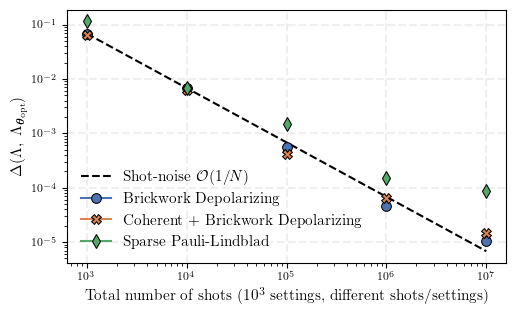

In [27]:
markersize = 7
capsize = 5

markers = ['o', 'X', 'd']
labels = ["Brickwork Depolarizing", "Coherent + Brickwork Depolarizing", "Sparse Pauli-Lindblad", "Sparse Pauli-Lindblad Hanoi"]

shots = np.array([10 ** int(k[2:]) for k in shots_keys])

fig = plt.figure(figsize=set_size(fraction=0.75))

# Shot-noise scaling
plt.plot(shots, 68 * shots**(-1.), color = "k", ls = "--", label = r"Shot-noise $\mathcal{O}(1/N)$")

# Noise with error-bars
for (k, vals_dicts), color, marker, label in zip(processed_data.items(), cmap, markers, labels):

    for s, v in zip(shots, vals_dicts.values()):
        plt.plot(s, v[0], color = color, marker = marker,  markersize = markersize, markeredgecolor='black', mew=0.75)
    plt.errorbar([], [], color = color, marker = marker, markersize = markersize, capsize = capsize, markeredgecolor='black', label=label, mew=0.75)

plt.yscale('log')
plt.xscale('log')
plt.xlabel(r"Total number of shots ($10^3$ settings, different shots/settings)")
plt.ylabel(r"$\Delta(\Lambda,~\Lambda_{\boldsymbol{\theta_\textrm{opt}}})$")

plt.legend(loc=3, frameon=False)

plt.grid(ls = "--", lw = 1.5, alpha = 0.2)

plt.tight_layout()
plt.savefig('delta_accuracy_vs_shots-noerrorbars.pdf', format="pdf")

In [ ]:
for shots in shots_keys:
    for metric in metrics_keys:
        data_per_shots[shots][metric] = np.real_if_close(np.array(data_per_shots[shots][metric]), tol=1e-12)    
        
        x = data_per_shots[shots][metric]

        min_loss = np.min(xx) 

        ###########################
        # Check dimensions of data (if different prolongate shorter with same value to compute values)
        ###########################
        training_epochs = [len(xx) for xx in x]
        
        # If optimisation finished at different epochs
        if not np.all(np.isclose(training_epochs, training_epochs[0])):
            e_max = max(training_epochs)
            x_new = np.zeros((len(x), e_max))
            for i, xx in enumerate(x):
                xx = np.hstack([xx, [xx[-1]] * (e_max - len(xx))]) # Homogenise data to the longest training run
                x_new[i] = xx
            x = x_new
        ###########################

        # Mean and standard deviation
        mu, std = np.mean(x, axis=0), np.std(x, axis=0)

        data_per_shots[shots]['avg_' + metric] = mu
        data_per_shots[shots]['std_' + metric] = std

In [ ]:
plt.plot(data_per_shots['1e3']['avg_test_loss'])

In [ ]:
np.all(np.isclose(numbers, numbers[0]))

In [ ]:
averaged_data['1e3']['frob_distance'] = np.array(averaged_data['1e3']['frob_distance'])

In [ ]:
averaged_data['1e3']['frob_distance']